# Validate spectra (buoy vs reconstruction)

Compare **observed buoy spectra** to reconstructed metamodel spectra:

- **Buoy** — processed NetCDF (`Efth` on native freq/dir grid)
- **Bulk reconstruct** — `mm.reconstruct(..., spectral=False)` + `save_spectra`
- **Partition reconstruct** — `mm.reconstruct(..., spectral=True)` (WHACS partitions 0–3 summed)

Plots: ~12 random hourly timesteps, monthly mean, and seasonal mean for the selected
`period`.

**Prerequisites:** spectra caches under `tmp/reconstruct/` for the same `period`,
`sites`, and `mda_n` (`save_spectra: true` in `Samoa.json`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from utils.config import resolve
from utils.model import metamodel as mm
from utils.observation import onshore_sites as obs

## Configuration

In [2]:
period = "2020-07"
offshore_name = "WHACS"
mda_n = 450
pca_variance = 0.99
wl = 0.0
goals = None  # all goals

buoy_instruments = ["Aunuu_Buoy"]
sites = [obs.snapwave_site_id(iid) for iid in buoy_instruments]
site_id = sites[0]

buoy_raw_files = {
    obs.snapwave_site_id("Aunuu_Buoy"): (
        "inputs/Observations/processed/buoy_Anuu_with_spectra.nc"
    ),
}

n_random = 12
random_seed = 42
facet_col_wrap = 4
plot_batch = 4  # timesteps per figure

recon_kw = dict(
    n=mda_n,
    offshore_name=offshore_name,
    goals=goals,
    wl=wl,
    site_ids=sites,
    pca_variance=pca_variance,
)

print("Observations JSON:", obs.geojson_path())
print(f"period   : {period}")
print(f"site     : {site_id}")

Observations JSON: /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/Observations/Samoa_observations.json
period   : 2020-07
site     : buoy_Aunuu_Buoy


## 1 · Load spectra

In [3]:
buoy_raw = xr.open_dataset(resolve(buoy_raw_files[site_id])).sel(time=period)
spec_var = "Efth" if "Efth" in buoy_raw else "efth"
buoy_efth = buoy_raw[spec_var]

bulk_spec = mm.load_reconstruction_spectra(
    period, spectral=False, load=False, **recon_kw
)
part_spec = mm.load_reconstruction_spectra(
    period, spectral=True, load=False, **recon_kw
)

for label, ds in [("bulk", bulk_spec), ("partition", part_spec)]:
    if ds is None:
        raise FileNotFoundError(
            f"Missing {label} spectra cache for {period!r} — run "
            f"mm.reconstruct(..., spectral={label == 'partition'}, recompute=True) "
            "with save_spectra=true in Samoa.json."
        )

bulk_efth = bulk_spec["efth"].sel(sites=site_id)
part_efth = part_spec["efth"].sel(sites=site_id)

print("Buoy :", dict(buoy_efth.sizes))
print("Bulk :", dict(bulk_efth.sizes))
print("Part :", dict(part_efth.sizes))

2026-07-14 12:17:44,595 - hyglow.metamodel - INFO - Loading reconstruction cache: reconstruct-v5__reconstruct__offshore-WHACS__n-450__bulk__goals-all__wl-0__sites-buoy_Aunuu_Buoy__vars-dir-dm-hs-hs-spr-dspr-tp-tp__pca-dir0.99_hs0.99_spr0.99__cfg-b6ae470f__time-2020-07__spectra.nc
2026-07-14 12:17:44,610 - hyglow.metamodel - INFO - Loading reconstruction cache: reconstruct-v5__reconstruct__offshore-WHACS__n-450__spectral__goals-all__wl-0__sites-buoy_Aunuu_Buoy__vars-dir-dm-hs-hs-spr-dspr-tp-tp__pca-dir0.99_hs0.99_spr0.99__cfg-b6ae470f__time-2020-07__spectra.nc


Buoy : {'time': 744, 'freq': 56, 'dir': 72}
Bulk : {'time': 744, 'freq': 29, 'dir': 72}
Part : {'time': 744, 'freq': 29, 'dir': 72}


## 2 · Helpers

In [4]:
def pick_random_time_index(n: int, n_time: int, seed: int) -> np.ndarray:
    """Sorted integer indices along ``time``."""
    rng = np.random.default_rng(seed)
    n_pick = min(n, n_time)
    return np.sort(rng.choice(n_time, size=n_pick, replace=False))


def monthly_mean_spectra(da: xr.DataArray) -> list[tuple[str, xr.DataArray]]:
    """One time-averaged spectrum per calendar month (no groupby facet dim)."""
    months = sorted({int(m) for m in da["time"].dt.month.values})
    return [
        (
            f"month={month}",
            da.sel(time=da.time.dt.month == month).mean("time", skipna=True),
        )
        for month in months
    ]


def seasonal_mean_spectra(da: xr.DataArray) -> list[tuple[str, xr.DataArray]]:
    """One time-averaged spectrum per season (DJF/MAM/JJA/SON)."""
    seasons = sorted({str(s) for s in da["time"].dt.season.values})
    return [
        (
            f"season={season}",
            da.sel(time=da.time.dt.season == season).mean("time", skipna=True),
        )
        for season in seasons
    ]


def plot_spec_one(da: xr.DataArray, title: str) -> None:
    """Single polar spectrum (safe for time-averaged fields)."""
    da.spec.plot()
    plt.title(title)
    plt.tight_layout()
    plt.show()
    plt.close("all")


def plot_spec_list(specs: list[tuple[str, xr.DataArray]], title_prefix: str) -> None:
    """Plot several spectra sequentially (avoids wavespectra ``col=`` segfaults)."""
    for label, spec in specs:
        plot_spec_one(spec, f"{title_prefix} — {label}")


def plot_spec_time_facets(
    da: xr.DataArray,
    title: str,
    *,
    col_wrap: int = 6,
    batch: int | None = None,
) -> None:
    """Faceted plot along ``time`` only (``col=month`` / ``col=season`` crash wavespectra)."""
    nfacets = int(da.sizes["time"])
    step = batch or nfacets
    for start in range(0, nfacets, step):
        part = da.isel(time=slice(start, start + step))
        n = int(part.sizes["time"])
        nrows = int(np.ceil(n / col_wrap))
        figsize = (3.2 * col_wrap, 2.8 * nrows)
        part.spec.plot(col="time", col_wrap=col_wrap, figsize=figsize)
        suffix = ""
        if step < nfacets:
            suffix = f" (timesteps {start + 1}–{start + n})"
        plt.suptitle(f"{title}{suffix}", y=1.02)
        plt.show()
        plt.close("all")


sample_idx = pick_random_time_index(n_random, buoy_efth.sizes["time"], random_seed)
sample_buoy = buoy_efth.isel(time=sample_idx)
sample_bulk = bulk_efth.isel(time=sample_idx)
sample_part = part_efth.isel(time=sample_idx)

print(f"Random sample: {len(sample_idx)} timesteps (seed={random_seed})")
print("Sample times:", sample_buoy.time.values[:3], "...")

Random sample: 12 timesteps (seed=42)
Sample times: ['2020-07-03T15:00:00.000000000' '2020-07-03T17:00:00.000000000'
 '2020-07-03T21:00:00.000000000'] ...


## 3 · Random timesteps (~24)

Independent draws on a shared hourly time axis (buoy and reconstruction times match).

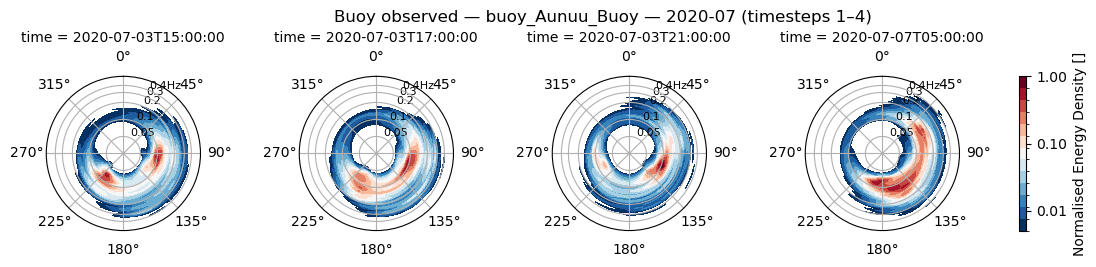

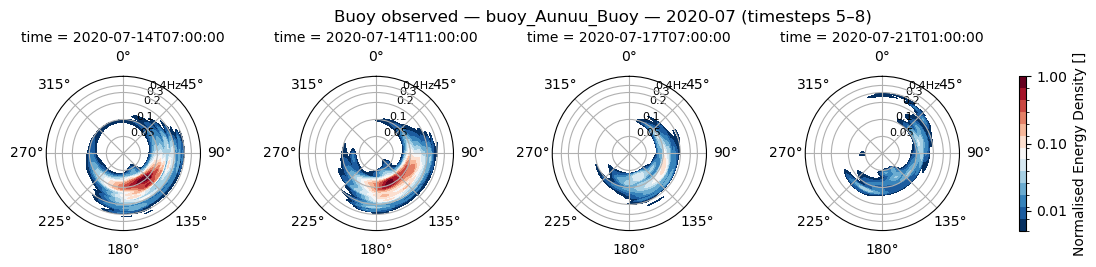

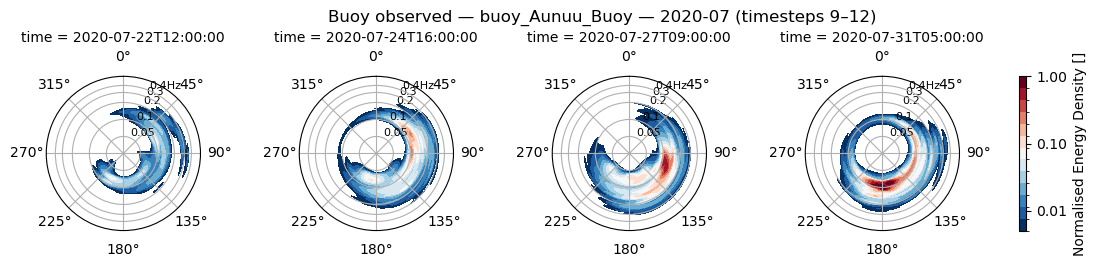

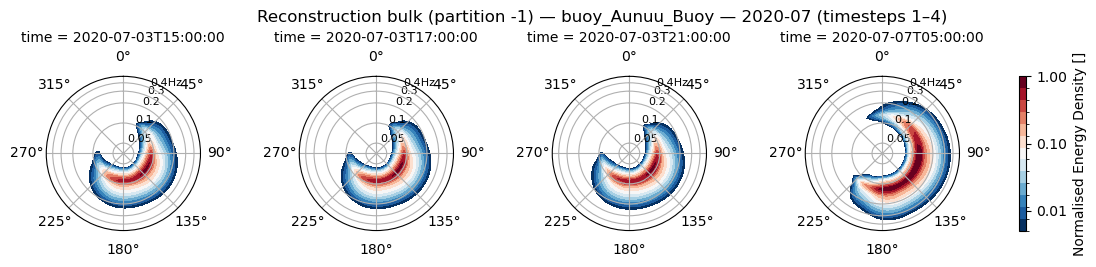

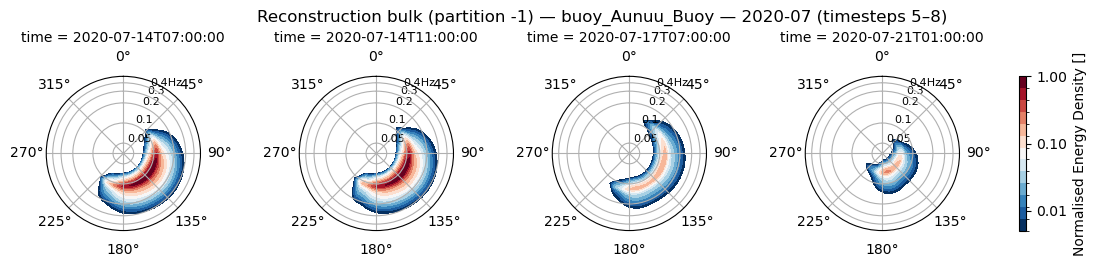

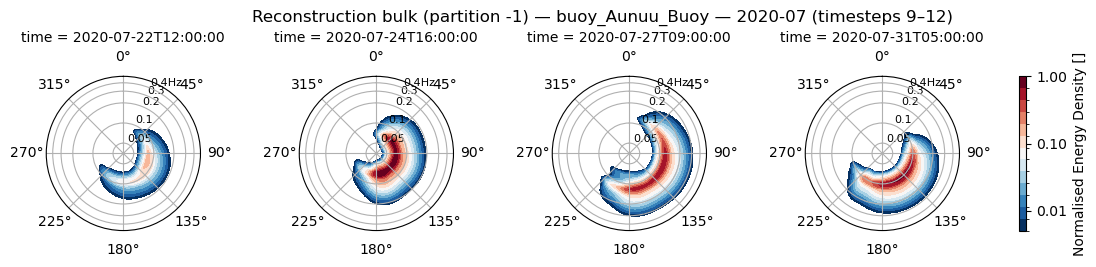

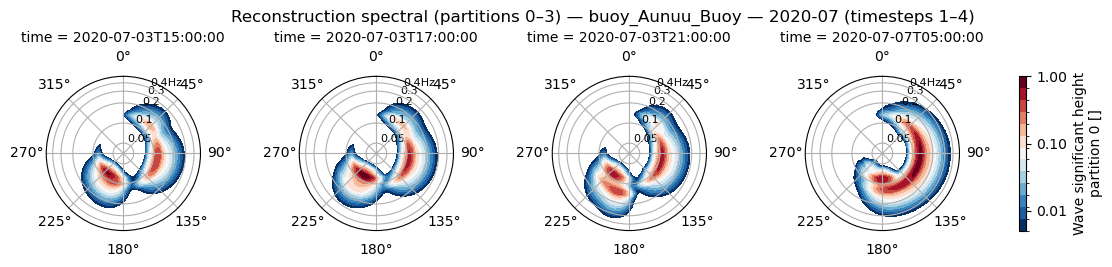

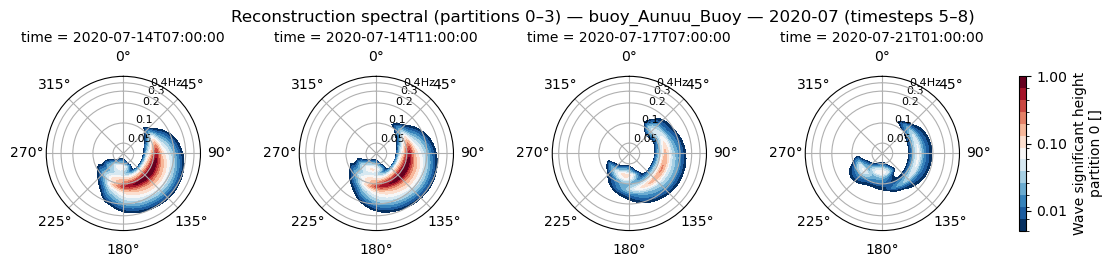

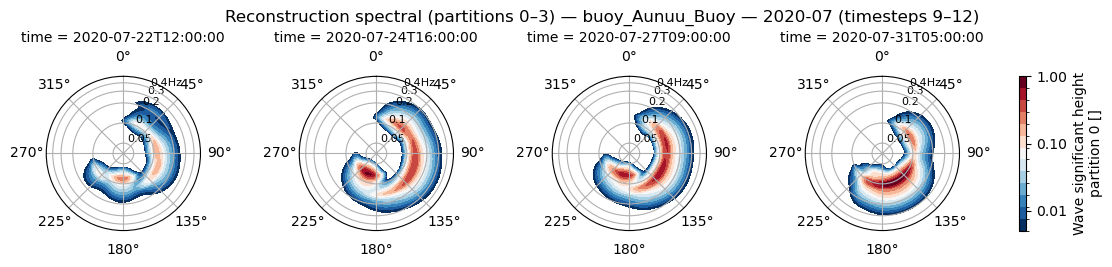

In [5]:
plot_spec_time_facets(
    sample_buoy.load(),
    f"Buoy observed — {site_id} — {period}",
    col_wrap=facet_col_wrap,
    batch=plot_batch,
)
plot_spec_time_facets(
    sample_bulk.load(),
    f"Reconstruction bulk (partition -1) — {site_id} — {period}",
    col_wrap=facet_col_wrap,
    batch=plot_batch,
)
plot_spec_time_facets(
    sample_part.load(),
    f"Reconstruction spectral (partitions 0–3) — {site_id} — {period}",
    col_wrap=facet_col_wrap,
    batch=plot_batch,
)

## 4 · Monthly mean spectra

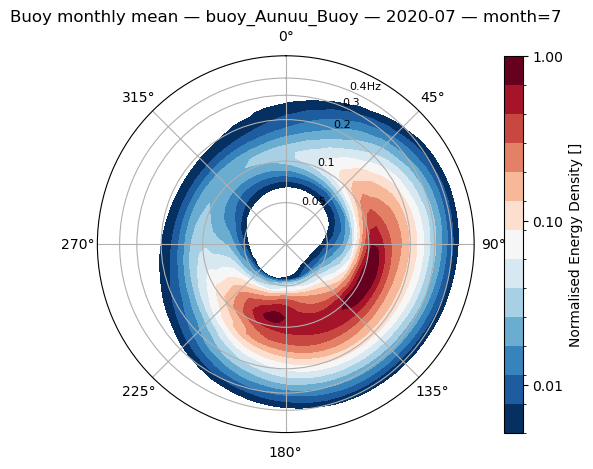

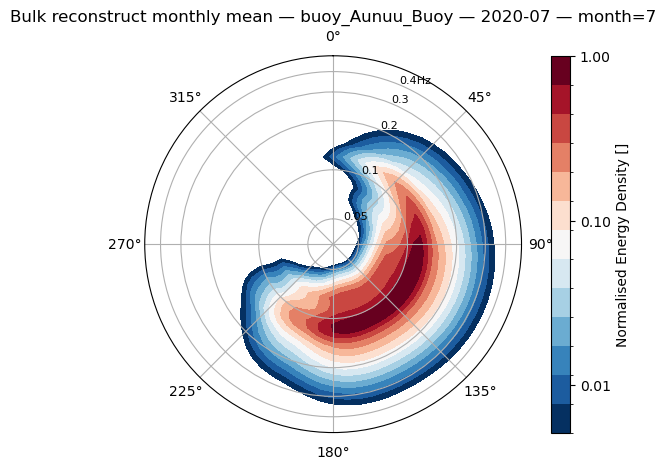

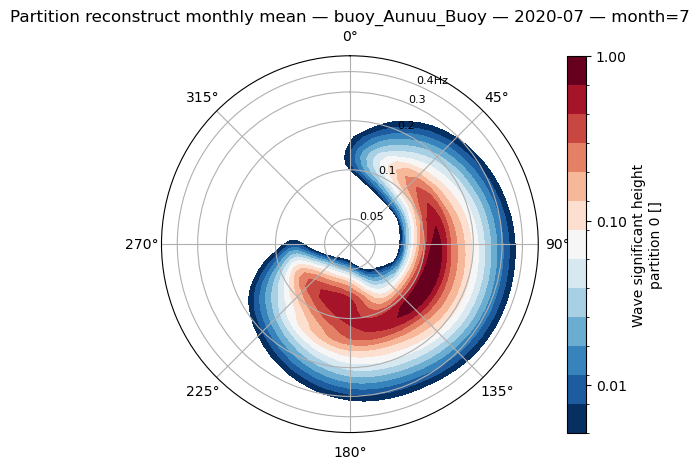

In [6]:
plot_spec_list(
    monthly_mean_spectra(buoy_efth.load()),
    f"Buoy monthly mean — {site_id} — {period}",
)
plot_spec_list(
    monthly_mean_spectra(bulk_efth.load()),
    f"Bulk reconstruct monthly mean — {site_id} — {period}",
)
plot_spec_list(
    monthly_mean_spectra(part_efth.load()),
    f"Partition reconstruct monthly mean — {site_id} — {period}",
)

## 5 · Seasonal mean spectra

Meteorological seasons (`DJF`, `MAM`, …). For a single calendar month there is
typically one season in the sample.

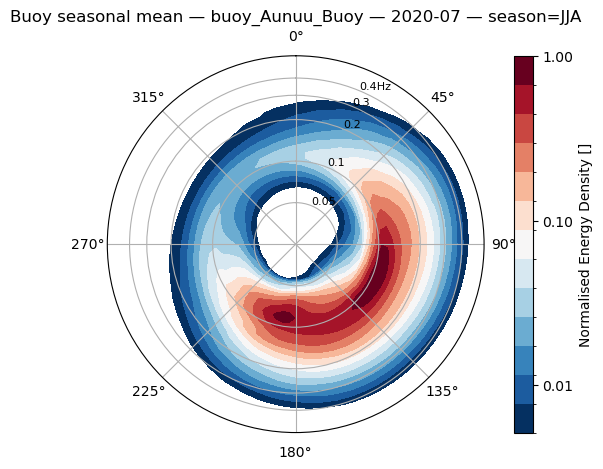

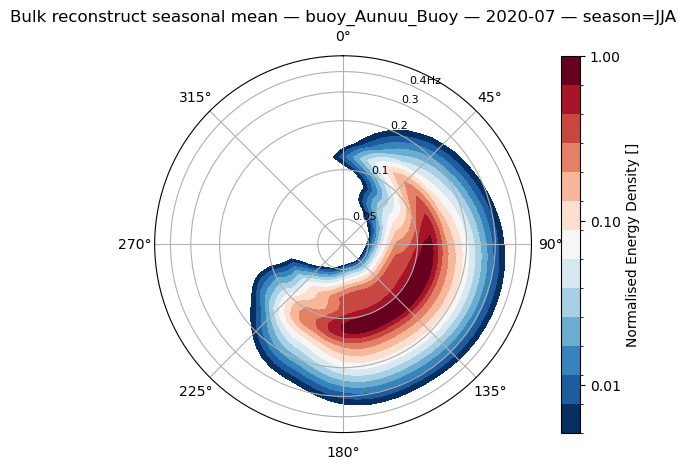

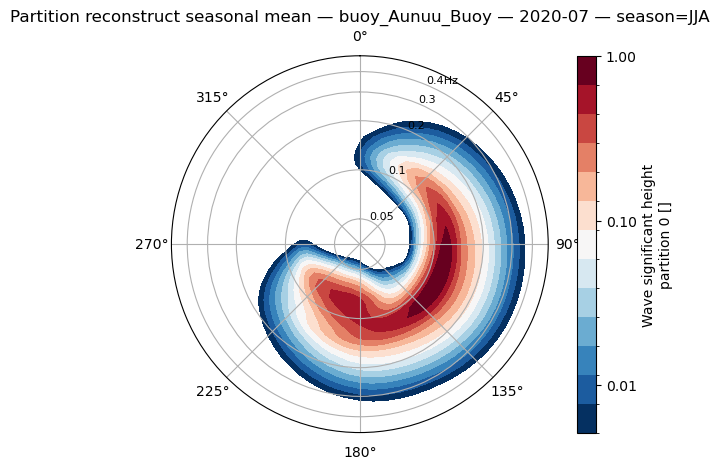

In [7]:
plot_spec_list(
    seasonal_mean_spectra(buoy_efth),
    f"Buoy seasonal mean — {site_id} — {period}",
)
plot_spec_list(
    seasonal_mean_spectra(bulk_efth),
    f"Bulk reconstruct seasonal mean — {site_id} — {period}",
)
plot_spec_list(
    seasonal_mean_spectra(part_efth),
    f"Partition reconstruct seasonal mean — {site_id} — {period}",
)